In [1]:
import pandas as pd
import joblib

# 학습 끝난 모델 2개
model_rent   = joblib.load('../models/model_rent_v1.pkl')
model_return = joblib.load('../models/model_return_v1.pkl')

# test 데이터 (실제값과 비교해야 하니까. 날씨/미세먼지도 이미 붙어있음)
test = pd.read_csv('../preprocessing/test.csv')
test['date'] = pd.to_datetime(test['date'])

# 학습 때와 동일한 전처리 (training-serving skew 방지, 아까 배운 그거)
X_cols = ['station_id', 'hour', 'dow', 'is_weekend', 'month', 'is_holiday',
          'temp', 'humid', 'wind', 'precip', 'pm10', 'pm25', 'ozone']

def prep(df):
    X = df[X_cols].copy()
    X['station_id'] = X['station_id'].astype('category')
    return X

print(f"test 기간: {test['date'].min().date()} ~ {test['date'].max().date()}")
print(f"스테이션: {sorted(test['station_id'].unique())}")

test 기간: 2026-02-01 ~ 2026-02-28
스테이션: ['ST0056', 'ST0065', 'ST0082', 'ST0107', 'ST0342', 'ST0627', 'ST0628', 'ST0639', 'ST0641', 'ST0642', 'ST0685', 'ST0720', 'ST0934', 'ST1067', 'ST1089', 'ST1302', 'ST1303', 'ST1330', 'ST1334']


In [2]:
# 나중에 달력 위젯으로 바꿀 부분. 지금은 값 바꿔가며 테스트
TARGET_DATE = '2026-02-10'
STATION     = 'ST0065'      # 대전역

# 그날 그 스테이션의 24시간치 행을 가져옴
day = test[(test['date'] == TARGET_DATE) & (test['station_id'] == STATION)].sort_values('hour')
print(f"{TARGET_DATE} {STATION}: {len(day)}행")   # 24가 나와야 정상

2026-02-10 ST0065: 24행


In [3]:
X_day = prep(day)

result = pd.DataFrame({
    'hour':        day['hour'].values,
    '대여_실제':   day['rent_cnt'].values,
    '대여_예측':   model_rent.predict(X_day).round(2),
    '반납_실제':   day['return_cnt'].values,
    '반납_예측':   model_return.predict(X_day).round(2),
})
print(result.to_string(index=False))

 hour  대여_실제  대여_예측  반납_실제  반납_예측
    0      0   0.05      0   0.10
    1      0   0.03      0   0.06
    2      0   0.03      0   0.04
    3      0   0.03      0   0.04
    4      0   0.03      0   0.04
    5      0   0.15      4   0.98
    6      3   0.57      5   1.74
    7      2   1.81      2   2.22
    8      2   2.18      5   2.20
    9      4   2.16      7   2.05
   10      2   1.80      1   2.03
   11      1   1.92      3   1.97
   12      0   2.17      0   2.38
   13      3   2.40      1   2.65
   14      4   2.25      1   2.37
   15      0   2.35      1   2.25
   16      3   2.05      2   2.09
   17      3   2.17      1   2.07
   18      5   2.05      1   2.12
   19      3   1.64      1   1.47
   20      1   1.14      1   1.00
   21      0   1.08      1   0.85
   22      1   1.01      1   0.76
   23      1   0.92      1   0.55


In [6]:
print(f"대여 — 실제 합: {result['대여_실제'].sum()}건 / 예측 합: {result['대여_예측'].sum():.1f}건")
print(f"반납 — 실제 합: {result['반납_실제'].sum()}건 / 예측 합: {result['반납_예측'].sum():.1f}건")

대여 — 실제 합: 38건 / 예측 합: 32.0건
반납 — 실제 합: 39건 / 예측 합: 34.0건


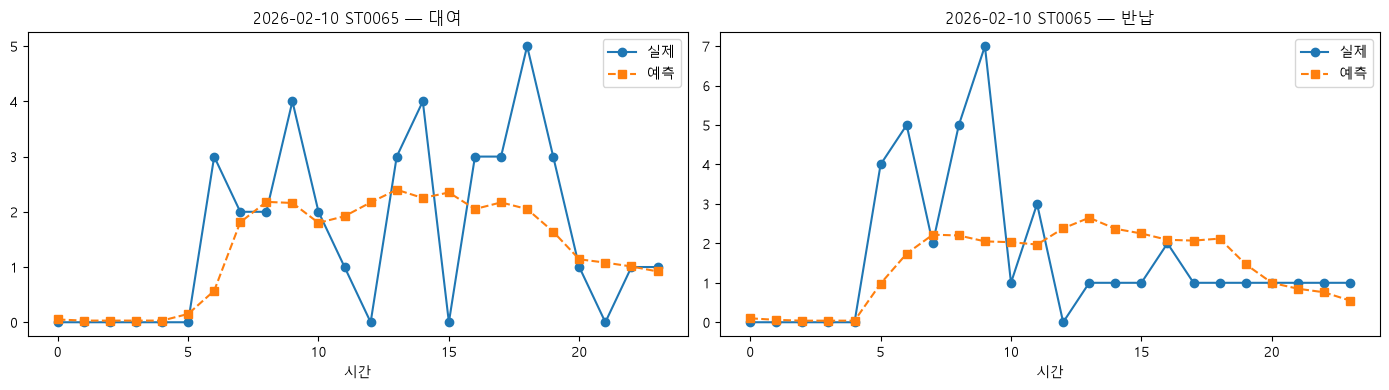

In [5]:
import matplotlib.pyplot as plt
plt.rc('font', family='Malgun Gothic')   # 윈도우 한글 폰트
plt.rc('axes', unicode_minus=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(result['hour'], result['대여_실제'], 'o-', label='실제')
axes[0].plot(result['hour'], result['대여_예측'], 's--', label='예측')
axes[0].set_title(f'{TARGET_DATE} {STATION} — 대여')
axes[0].set_xlabel('시간'); axes[0].legend()

axes[1].plot(result['hour'], result['반납_실제'], 'o-', label='실제')
axes[1].plot(result['hour'], result['반납_예측'], 's--', label='예측')
axes[1].set_title(f'{TARGET_DATE} {STATION} — 반납')
axes[1].set_xlabel('시간'); axes[1].legend()

plt.tight_layout()
plt.show()